# Wetterbilder klassifizieren mit Convolutional Neural Network
# Deep Learning Algorithmus, der anhand den Fotos von dem Kaggle Image Dataset lernt Bilder in Wetterkategorien zu klassifizieren.

# Bibliotheken importieren

In [1]:
import kagglehub      # kagglehub: Datensätze direkt von Kaggle herunterladen                                  
import cv2            # OpenCV: Bildverarbeitung
import os             # Zum Arbeiten mit Dateien und Ordnern
import numpy as np    # NumPy: Standardbibliothek für Arrays
from sklearn.model_selection import train_test_split    # Scikit-learn: Daten in Trainings- Test- und Validationsets aufteilen
import torch                                            # PyTorch: Deep Learning Bibliothek: Neuronale Netze, Optimierer, Loss-Funktionen
from torch.utils.data import Dataset, DataLoader        # Pytorch Klassen für die Arbeit mit Datensätzen und DataLoadern
import torch.nn as nn                                   # PyTorch: Neuronale Netze
from torchinfo import summary                           # PyTorch: Modellzusammenfassung
import torch.optim as optim                             # PyTorch: Optimierer für neuronale Netze
import matplotlib.pyplot as plt                         # Matplotlib: Visualisierung von Daten
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report     # Scikit-learn: Metriken für die Bewertung von Klassifikationsmodellen


# Datensatz herunterladen und Pfad speichern:
Die Daten werden automatisch in C:\Users\User\.cache\kagglehub\datasets\somesh24... heruntergeladen und entpackt.
Der Pfad wird in der Variable "path" gespeichert.

In [2]:
path = kagglehub.dataset_download("somesh24/multiclass-images-for-weather-classification")   
                                                                                            
print(path)

C:\Users\mxrbe\.cache\kagglehub\datasets\somesh24\multiclass-images-for-weather-classification\versions\1


# Klassen definieren:
Wir definieren die Klassen, die wir für die Klassifikation verwenden werden. 
Jede Klasse repräsentiert eine Wetterbedingung.
Die ursprüngliche Klasse "Shine" wurde in "Sunshine" umbenannt, um die eindeutiger zu machen.

In [3]:
classes = ["Cloudy", "Rainy", "Sunshine", "Sunrise"]

label_map = {
    "Cloudy": 0,
    "Rainy": 1,
    "Sunshine": 2,
    "Sunrise": 3}

# Eine Liste von allen Bilder erstellen:
samples.append erstellt eine Liste von Tupeln, wobei jedes Tupel den Pfad zu einem Bild und das zugehörige Label enthält.
e.g: samples = [("Cloudy/cloudy1.jpg", 0), ("Rainy/rainy1.jpg", 1), ...]

In [4]:
samples = []

for class_name in classes:

    folder = os.path.join(path, class_name)

    for file in os.listdir(folder):

        samples.append((os.path.join(folder, file), label_map[class_name]))

print("Anzahl Bilder:", len(samples))



Anzahl Bilder: 1124


# Die Daten in 3 Sätze aufteilen: 
Training: 75%, Validierung: 15%, Test: 10%
Die 10 % Testdaten werden nicht für das Training oder für die Validierung verwendet,sondern dienen nur zur abschließenden Bewertung des Modells.
Mit stratify wird versucht, dieselbe Klassenverteilung in den Teilmengen beizubehalten.

In [5]:
train_samples, valid_samples = train_test_split(
    samples,
    test_size=0.25,
    random_state=42,
    stratify=[label for _, label in samples])

valid_samples, test_samples = train_test_split(
    valid_samples,
    test_size=0.4,
    random_state=42,
    stratify=[label for _, label in valid_samples])

# Die Klasse WeatherDataset definieren:
Die Klasse WeatherDataset erbt von torch.utils.data.Dataset, und implementiert die Methoden __len__ und __getitem__, um die Daten für das Training, die Validierung und den Test bereitzustellen.
Die Klasse beschreibt, wie die Bilder (1 Bild) geladen, vorverarbeitet und in Tensoren umgewandelt werden.

In [6]:
class WeatherDataset(Dataset):
    def __init__(self, samples, image_size=128):        # __init__ ist der Constructor der Klasse, der die Liste der Samples und die Bildgröße als Parameter erhält. 
        self.samples = samples
        self.image_size = image_size

    def __len__(self):                                  # __len__ gibt die Anzahl der Samples im Dataset zurück.
        return len(self.samples)
    
    def __getitem__(self, idx):                         # __getitem__ lädt ein Bild und das zugehörige Label anhand des Index idx. 

        image_path, label = self.samples[idx]
        img = cv2.imread(image_path)

        if img is None:
            raise FileNotFoundError(image_path)
        
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)                  # Die Bilder werden von OpenCV im BGR-Format geladen, wir konvertieren sie in RGB-Format.
        img = cv2.resize(img, (self.image_size, self.image_size))   # Die Bilder werden auf die gewünschte Größe (image_size x image_size) skaliert.
        img = img.astype("float32") / 255                           # Die Pixelwerte werden von [0, 255] auf [0, 1] normalisiert.
        img = torch.from_numpy(img)                                 # Die Bilder werden von NumPy-Arrays in PyTorch-Tensoren umgewandelt.
        img = img.permute(2,0,1)                                    # Die Dimensionen des Tensors werden von (Höhe, Breite, Kanäle) in (Kanäle, Höhe, Breite) geändert, da PyTorch diese Reihenfolge erwartet. 

        label = torch.tensor(label)                                 # Die Labels werden in PyTorch-Tensoren umgewandelt, um sie mit den Ausgaben des Modells vergleichen zu können.

        return img, label

# Instanzen für die Klasse WeatherDataset erstellen:
Wir erstellen Instanzen der WeatherDataset-Klasse für das Training, die Validierung und den Test.

In [7]:
train_dataset = WeatherDataset(train_samples)
valid_dataset = WeatherDataset(valid_samples)
test_dataset = WeatherDataset(test_samples)

# Instanzen für die Klasse DataLoader erstellen:
Wir erstellen DataLoader-Instanzen für das Training, die Validierung und den Test.
batch_size=32 bedeutet, dass 32 Bilder gleichzeitig verarbeitet werden.
Bei 1124 Bildern im Trainingssatz bedeutet dies, dass 1124/32 = 35,125 -> 36 Batches pro Epoche verarbeitet werden.

In [8]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True)           # Zufällige Anordnung der Trainingsdaten, um Overfitting zu vermeiden.

valid_loader = DataLoader(
    valid_dataset,
    batch_size=32,
    shuffle=False)          # Keine zufällige Anordnung der Validierungsdaten nötig. Es wird nicht trainiert.

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False)          # Keine zufällige Anordnung der Validierungsdaten nötig. Es wird nicht trainiert.

# Plausibilitätsprüfung der DataLoader

In [9]:
images, labels = next(iter(train_loader))

print(images.shape)     # Die Form des Tensors images sollte (32, 3, 128, 128) sein, was bedeutet, dass wir 32 Bilder mit 3 Kanälen (RGB) und einer Größe von 128x128 Pixeln haben.
print(labels.shape)     # Die Form des Tensors labels sollte (32,) sein, was bedeutet, dass wir 32 Labels für die 32 Bilder haben.

torch.Size([32, 3, 128, 128])
torch.Size([32])


# Convolutional Neural Network definieren:
Ein Convolutional Neural Network kann Mustern und Räumlichen Beziehungen in Bildern erkennen.
Das CNN besteht aus 2 großen Bereichen: Feature Extraction und Classification. 

In [10]:
model = nn.Sequential(

# Feature Extraction durch Convolutional Layers:
# Während der Convolution wird der Anzahl der Kanäle erhöht, während die Höhe und Breite der Bilder reduziert wird.

# 1. Convolutional Layer Input: (3 x 128 x 128) Output: (32 x 64 x 64)

    nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

# 2. Convolutional Layer Input: (32 x 64 x 64) Output: (64 x 32 x 32)

    nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

# 3. Convolutional Layer Input: (64 x 32 x 32) Output: (128 x 16 x 16)

    nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

# Classification:

    nn.Flatten(),                   # Eindimensionale Vektor erstellen: 128 x 16 x 16 = 32768

    nn.Linear(128 * 16 * 16, 256),  #  Fully connected Layer mit 256 Neuronen und 32768 Eingangswerten
    nn.ReLU(),

    nn.Dropout(0.5),                # Dropout-Schicht, um Overfitting zu vermeiden. Bei 50% der Neuronen wird die Aktivierung auf 0 gesetzt.
                                     
    nn.Linear(256, 4))              # Output Schicht 256 Eingänge und 4 Neuronen, da wir 4 Klassen haben.

summary(model, input_size=(1, 3, 128, 128))     # Diese Funktion zeigt eine detaillierte Zusammenfassung des neuronalen Netzwerks

criterion = nn.CrossEntropyLoss()      # Mit dem Loss Funktion wird die Differenz zwischen vorhergesagten und tatsächlichen Labels berechnet.

optimizer = optim.Adam(model.parameters(), lr=0.001) # Der Optimizer verändert die trainierbaren Parameter des neuronalen Netzwerks.


# Convolutional Neural Network trainieren und validieren:

In [11]:
epochs = 20             # In jeder Epoche wird das gesamte Trainingsset einmal durchlaufen.

best_accuracy = 0       # Hier wird die beste Validierungsgenauigkeit gespeichert, um das beste Modell zu speichern.

train_accuracies = []   
val_accuracies = []

train_losses = []
val_losses = []

# -------------- Training Loop -------------
# In jeder Epoche wird das Modell trainiert und anschließend auf dem Validierungsset validiert. 
# Die Genauigkeit und der Verlust werden für jede Epoche gespeichert, um sie später zu visualisieren.

for epoch in range(epochs):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:

        optimizer.zero_grad()               # Hier werden die Gradienten der trainierbaren Parameter auf 0 gesetzt, um sie für die aktuelle Epoche neu zu berechnen.

        outputs = model(images)             # Hier werden die Bilder durch das Modell geleitet, um die Vorhersagen zu erhalten.

        loss = criterion(outputs, labels)   # Vorhersage mit den Labels vergleichen.

        loss.backward()                     # Hier berechnet PyTorch die Gradienten der Loss-Function bezüglich der trainierbaren Parameters.

        optimizer.step()                    # Hier werden die trainierbaren Parameter des Modells aktualisiert, um den Loss zu minimieren.

        running_loss += loss.item()         # Loss aufsummieren 

        _, predicted = torch.max(outputs, 1)    # Hier wird die Klasse mit der höchsten Wahrscheinlichkeit als Vorhersage ausgewählt.

        total += labels.size(0)             # Hier wird die Gesamtzahl der Bilder im Trainingsset gezählt (32).

        correct += (predicted == labels).sum().item()   # Hier wird die Anzahl der korrekt vorhergesagten Labels gezählt.

    train_loss = running_loss/len(train_loader)         # Hier wird der durchschnittliche Loss für das Trainingsset berechnet.

    train_accuracy = 100 * correct / total              # Die Accuracy gibt an, wie viele Bilder korrekt klassifiziert wurden.

# ---------------- Validierung ----------------:

    model.eval()                                # Das Modell wird in den Evaluierungsmodus versetzt.

    running_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():                       # Automatische Berechnung der Gradienten wird deaktiviert, da wir nicht trainieren.
        for images, labels in valid_loader:     

            outputs = model(images)             # Die Validierungsbilder werden durch das Modell geleitet, um die Vorhersagen zu erhalten.

            loss = criterion(outputs, labels)   # Vorhersage mit den Labels vergleichen.

            running_loss += loss.item()         # Loss aufsummieren

            _, predicted = torch.max(outputs, 1)    # Hier wird die Klasse mit der höchsten Wahrscheinlichkeit als Vorhersage ausgewählt.

            total += labels.size(0)                 # Hier wird die Gesamtzahl der Bilder im Trainingsset gezählt (32)

            correct += (predicted == labels).sum().item()       # Vergleichen der Vorhersagen mit den tatsächlichen Labels und Zählen der korrekt vorhergesagten Labels.

    val_loss = running_loss/len(valid_loader)       # Kennzahlen der Validierung berechnen: Durchschnittlicher Loss 
    val_accuracy = 100 * correct / total            # und Accuracy

    train_losses.append(train_loss)                 # Die vier Kennzahlen werden für jede Epoch gespeichert.
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy) 

    print(f"Epoch {epoch+1:2d} | "                  # Trainings- und Validierung Accuracy ausgeben
        f"Train Accuracy: {train_accuracy:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%")    

    if val_accuracy > best_accuracy:                # Wenn die Validierungsgenauigkeit besser ist als die bisher beste Genauigkeit,
        best_accuracy = val_accuracy                # wird das Modell gespeichert. "torch.save" speichert die trainierbaren Parameter des Modells in einer Datei.
        torch.save(model.state_dict(), "best_weather_image_classification_cnn.pth")
        print("Best model saved with accuracy: {:.2f}%".format(best_accuracy))

Epoch  1 | Train Accuracy: 59.3120 | Val Accuracy: 82.14%
Best model saved with accuracy: 82.14%
Epoch  2 | Train Accuracy: 82.6809 | Val Accuracy: 82.74%
Best model saved with accuracy: 82.74%
Epoch  3 | Train Accuracy: 82.0878 | Val Accuracy: 85.71%
Best model saved with accuracy: 85.71%
Epoch  4 | Train Accuracy: 86.3582 | Val Accuracy: 91.07%
Best model saved with accuracy: 91.07%
Epoch  5 | Train Accuracy: 89.5611 | Val Accuracy: 87.50%
Epoch  6 | Train Accuracy: 90.5101 | Val Accuracy: 84.52%
Epoch  7 | Train Accuracy: 90.0356 | Val Accuracy: 90.48%
Epoch  8 | Train Accuracy: 91.6963 | Val Accuracy: 91.67%
Best model saved with accuracy: 91.67%
Epoch  9 | Train Accuracy: 92.4081 | Val Accuracy: 89.88%
Epoch 10 | Train Accuracy: 94.1874 | Val Accuracy: 88.10%
Epoch 11 | Train Accuracy: 93.8316 | Val Accuracy: 89.88%
Epoch 12 | Train Accuracy: 94.3060 | Val Accuracy: 92.26%
Best model saved with accuracy: 92.26%
Epoch 13 | Train Accuracy: 95.6109 | Val Accuracy: 91.67%
Epoch 14 | T

# Trainings- und Validierungs-Accuracy plotten:
Plotten der Trainings- und Validierungsgenauigkeit über die Epochen hinweg.

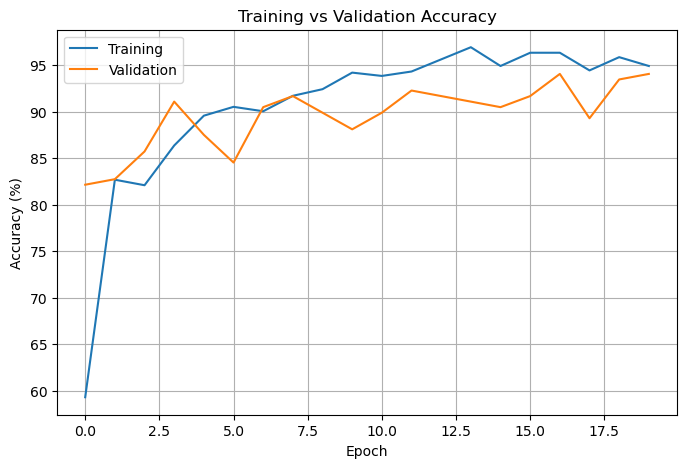

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(train_accuracies, label="Training")
plt.plot(val_accuracies, label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")

plt.legend()

plt.grid(True)

plt.show()

# Finale Validierung des Convolutional Neural Network:

In [13]:
model.load_state_dict(torch.load("best_weather_image_classification_cnn.pth")) # Wir nehmen das Modell mit der höchsten Validation Accuracy.

model.eval()                                    # Das Modell wird in den Evaluierungsmodus versetzt.

correct = 0
total = 0

y_true = []                                     # Liste für die tatsächlichen Labels
y_pred = []                                     # Liste für die vorhergesagten Labels

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        outputs = model(images)                 # Die Testbilder werden durch das Modell geleitet, um die Vorhersagen zu erhalten.

        _, predicted = torch.max(outputs,1)     # Hier wird die Klasse mit der höchsten Wahrscheinlichkeit als Vorhersage ausgewählt.

        total += labels.size(0)                 # Hier wird die Gesamtzahl der Bilder im Trainingsset gezählt

        correct += (predicted == labels).sum().item()   # Vergleichen der Vorhersagen mit den tatsächlichen Labels und Zählen der korrekt vorhergesagten Labels.

        y_true.extend(labels.cpu().numpy())             # Die tatsächlichen Labels werden in die Liste y_true gespeichert.
        y_pred.extend(predicted.cpu().numpy())          # Die vorhergesagten Labels werden in die Liste y_pred gespeichert.

test_accuracy = 100 * correct / total                   # Die Test Accuracy wird berechnet.

print(f"Test Accuracy: {test_accuracy:.2f}%")           # Die Test Accuracy wird ausgegeben.


Test Accuracy: 93.81%


# Classification Report:
Der Classification Report berechnet vier wichtige Kennzahlen:

precision: wie häufig ist die Vorhersage tatsächlich korrekt, wenn das Modell eine bestimmte Klasse vorhersagt

recall: Wie viele der tatsächlich vorhandenen Bilder einer Klasse erkennt mein NN

f1-score: kombiniert precision und recall in einer einzigen Kennzahl

support: Die Anzahl der tatsächlichen Vorkommen einer Klasse im Testset.

              precision    recall  f1-score   support

      Cloudy       1.00      0.87      0.93        30
       Rainy       1.00      0.86      0.93        22
    Sunshine       0.83      1.00      0.91        25
     Sunrise       0.95      1.00      0.97        36

    accuracy                           0.94       113
   macro avg       0.95      0.93      0.93       113
weighted avg       0.95      0.94      0.94       113

[[26  0  3  1]
 [ 0 19  2  1]
 [ 0  0 25  0]
 [ 0  0  0 36]]


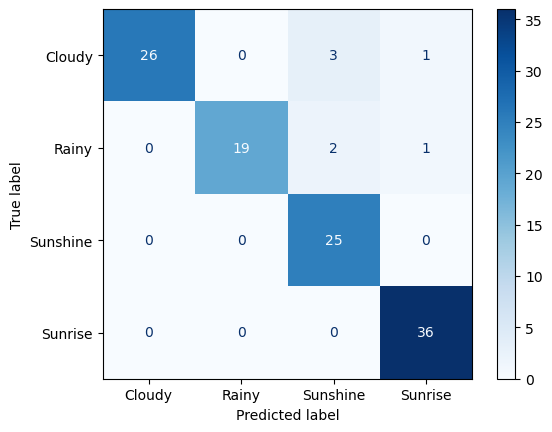

In [14]:
print(classification_report(y_true, y_pred, target_names=classes))  
                                                                    
cm = confusion_matrix(y_true, y_pred)                               
                                                                    
print(cm)                                                           

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)  # Die Confusion Matrix zeigt, welche Klassen das Netzwerk korrekt erkennt und welche Klassen es miteinander verwechselt.

disp.plot(cmap="Blues")

plt.show()